Cell 1 — Import libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


Cell 2 — Load and explore the dataset

In [ ]:
# ============================================================
# Cell 2 — Load and explore BOTH datasets (Iris + Breast Cancer)
# ============================================================
from sklearn.datasets import load_iris, load_breast_cancer

# ---------------- Dataset 1: Iris ----------------
iris = load_iris()

dataset = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
dataset["Species"] = iris.target

print("=" * 60)
print("IRIS DATASET")
print("=" * 60)

print("\nFirst five rows:")
print(dataset.head())

print("\nDataset shape:")
print(dataset.shape)

print("\nDataset information:")
dataset.info()

print("\nStatistical summary:")
print(dataset.describe())

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nDuplicate rows:")
print(dataset.duplicated().sum())

print("\nTarget classes:")
print(iris.target_names)

print("\nClass distribution:")
print(dataset["Species"].value_counts())


# ---------------- Dataset 2: Breast Cancer ----------------
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)
cancer_df["Target"] = cancer.target

print("\n" + "=" * 60)
print("BREAST CANCER DATASET")
print("=" * 60)

print("\nFirst five rows:")
print(cancer_df.head())

print("\nDataset shape:")
print(cancer_df.shape)

print("\nDataset information:")
cancer_df.info()

print("\nStatistical summary:")
print(cancer_df.describe())

print("\nMissing values:")
print(cancer_df.isnull().sum().sum())   

print("\nDuplicate rows:")
print(cancer_df.duplicated().sum())

print("\nTarget classes:")
print(cancer.target_names)

print("\nClass distribution:")
print(cancer_df["Target"].value_counts())

IRIS DATASET

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset shape:
(150, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null

Cell 3 — Visualize the dataset

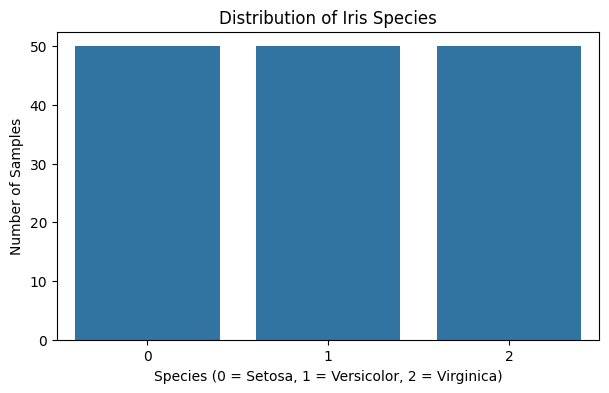

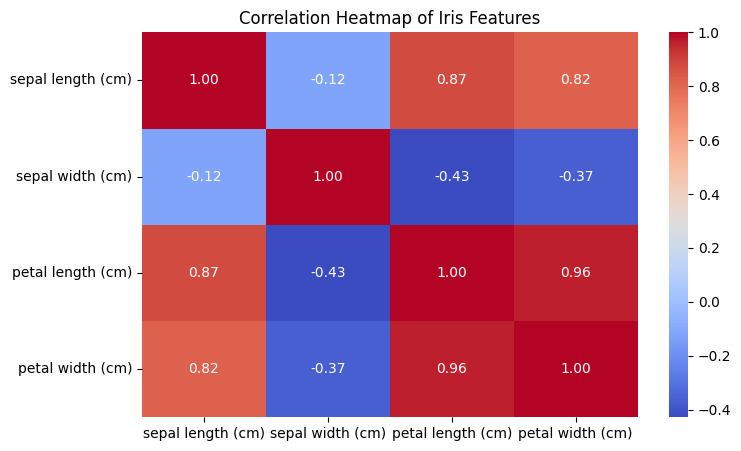

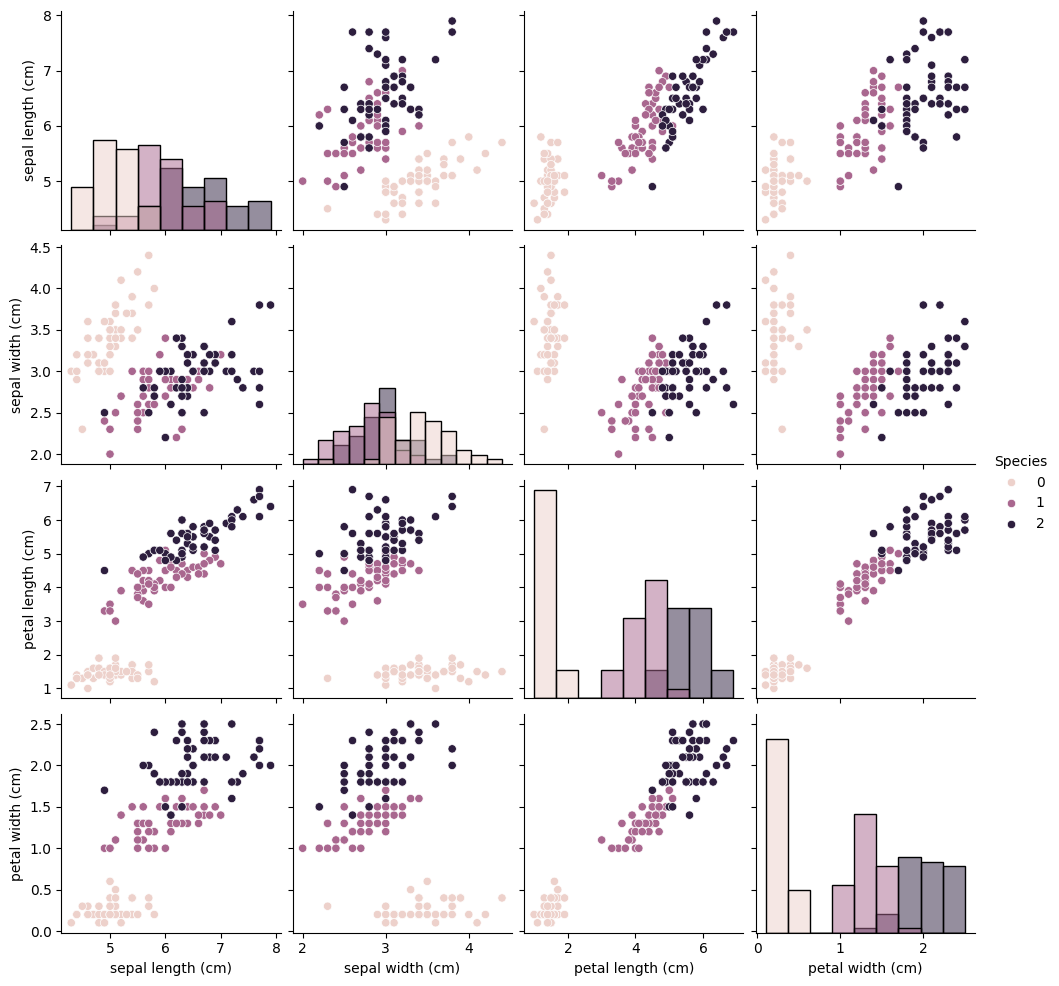

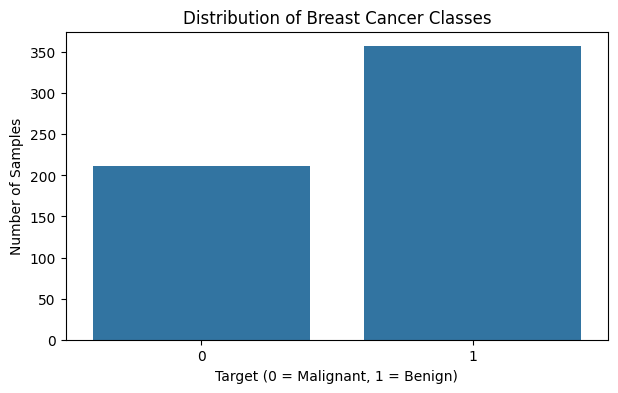

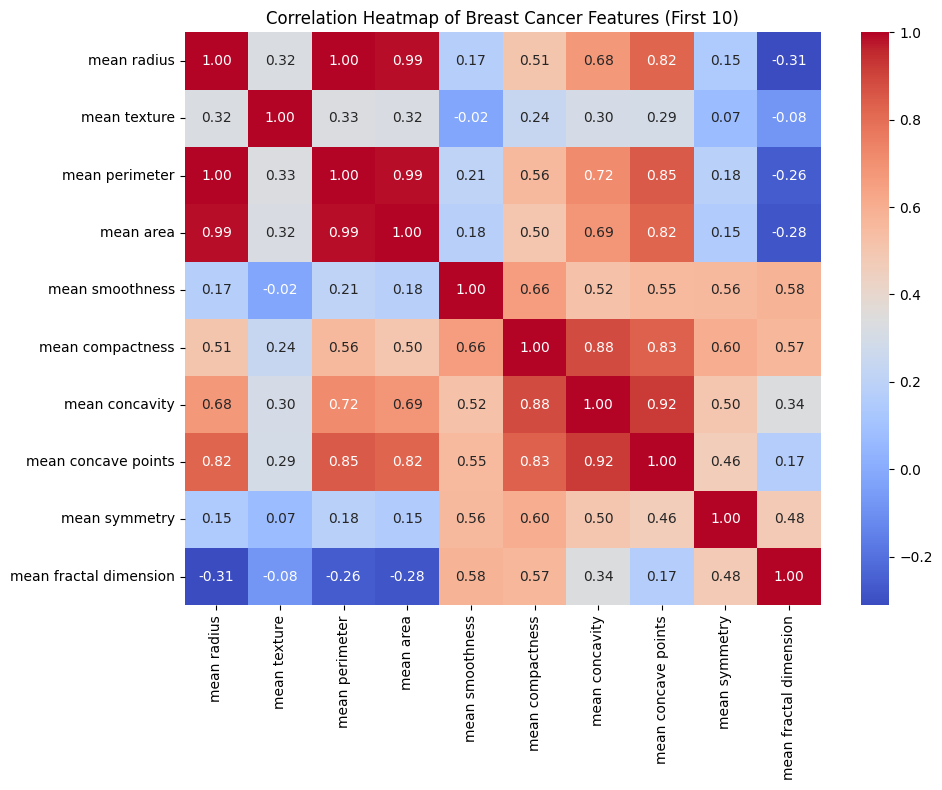

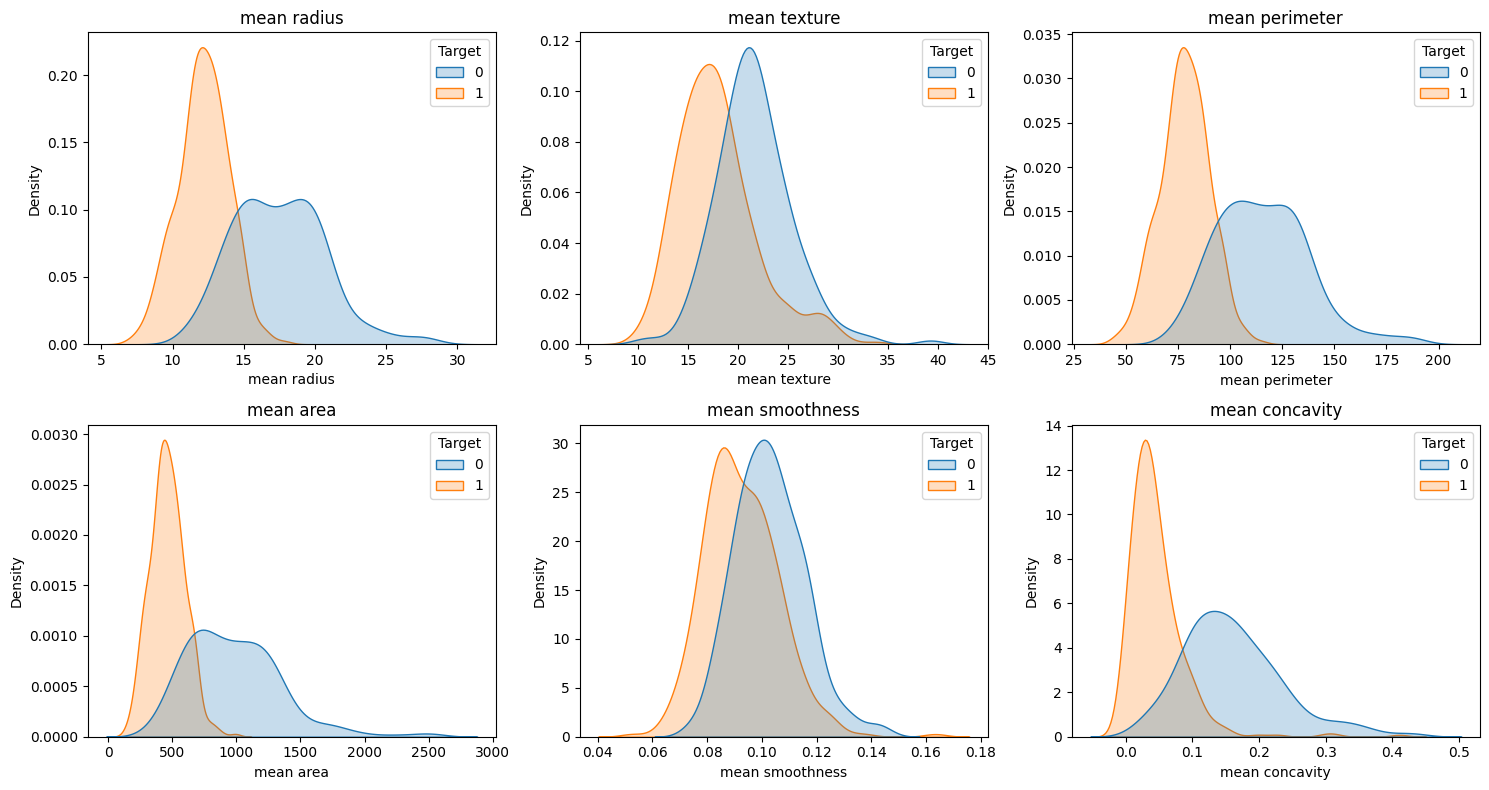

In [3]:
# ============================================================
# Cell 3 — Visualize BOTH datasets
# ============================================================

# ---------------- IRIS: Species distribution ----------------
plt.figure(figsize=(7, 4))
sns.countplot(
    data=dataset,
    x="Species"
)
plt.title("Distribution of Iris Species")
plt.xlabel("Species (0 = Setosa, 1 = Versicolor, 2 = Virginica)")
plt.ylabel("Number of Samples")
plt.show()

# ---------------- IRIS: Correlation heatmap ----------------
plt.figure(figsize=(8, 5))
sns.heatmap(
    dataset.iloc[:, :-1].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Iris Features")
plt.show()

# ---------------- IRIS: Pairplot ----------------
sns.pairplot(
    dataset,
    hue="Species",
    diag_kind="hist"
)
plt.show()


# ============================================================
# BREAST CANCER DATASET
# ============================================================

# ---------------- Breast Cancer: Class distribution ----------------
plt.figure(figsize=(7, 4))
sns.countplot(
    data=cancer_df,
    x="Target"
)
plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Target (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.show()

# ---------------- Breast Cancer: Correlation heatmap (first 10 features) ----------------
# All 30 features would be unreadable, so we take the first 10
plt.figure(figsize=(10, 8))
sns.heatmap(
    cancer_df.iloc[:, :10].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    cbar=True
)
plt.title("Correlation Heatmap of Breast Cancer Features (First 10)")
plt.tight_layout()
plt.show()

# ---------------- Breast Cancer: Distribution of key features by class ----------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity"
]

for ax, col in zip(axes.flat, key_features):
    sns.kdeplot(
        data=cancer_df,
        x=col,
        hue="Target",
        fill=True,
        common_norm=False,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

Cell 4 — Separate features and target, then split the data

In [4]:
# ============================================================
# Cell 4 — Split BOTH datasets (Iris + Breast Cancer)
# ============================================================

# ---------------- IRIS ----------------
# Input features
X = dataset.iloc[:, :-1].values

# Output labels
y = dataset["Species"].values

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("IRIS DATASET")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


# ---------------- BREAST CANCER ----------------
X_can = cancer_df.iloc[:, :-1].values
y_can = cancer_df["Target"].values

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_can,
    y_can,
    test_size=0.20,
    random_state=42,
    stratify=y_can
)

print("\nBREAST CANCER DATASET")
print("Training samples:", X_train_c.shape[0])
print("Testing samples:", X_test_c.shape[0])
print("Training feature shape:", X_train_c.shape)
print("Testing feature shape:", X_test_c.shape)

IRIS DATASET
Training samples: 120
Testing samples: 30
Training feature shape: (120, 4)
Testing feature shape: (30, 4)

BREAST CANCER DATASET
Training samples: 455
Testing samples: 114
Training feature shape: (455, 30)
Testing feature shape: (114, 30)


Cell 5 — Prepare features for each Naïve Bayes variant

In [ ]:
# ============================================================
# Cell 5 — Prepare features for each Naive Bayes variant (BOTH datasets)
# ============================================================

# ==========================================================
# IRIS DATASET (original, unchanged)
# ==========================================================

# ---------- Bernoulli Naive Bayes ----------
# Calculate thresholds using training data only
thresholds = np.median(X_train, axis=0)

# Convert features into binary values: 0 or 1
X_train_bernoulli = (X_train > thresholds).astype(int)
X_test_bernoulli = (X_test > thresholds).astype(int)


# ---------- Gaussian Naive Bayes ----------
# Keep the original continuous numerical features
X_train_gaussian = X_train.copy()
X_test_gaussian = X_test.copy()


# ---------- Multinomial Naive Bayes ----------
# Convert continuous features into five discrete bins
discretizer = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile"
)

X_train_multinomial = discretizer.fit_transform(X_train)
X_test_multinomial = discretizer.transform(X_test)

# MultinomialNB requires non-negative feature values
X_train_multinomial = X_train_multinomial.astype(int)
X_test_multinomial = X_test_multinomial.astype(int)


print("===== IRIS =====")
print("Bernoulli training data:")
print(X_train_bernoulli[:5])

print("\nGaussian training data:")
print(X_train_gaussian[:5])

print("\nMultinomial training data:")
print(X_train_multinomial[:5])


# ==========================================================
# BREAST CANCER DATASET 
# ==========================================================

# ---------- Bernoulli Naive Bayes ----------
thresholds_c = np.median(X_train_c, axis=0)

X_train_bernoulli_c = (X_train_c > thresholds_c).astype(int)
X_test_bernoulli_c = (X_test_c > thresholds_c).astype(int)


# ---------- Gaussian Naive Bayes ----------
# Continuous data → keep as-is, but standardize (recommended for GaussianNB)
from sklearn.preprocessing import StandardScaler

scaler_c = StandardScaler()
X_train_gaussian_c = scaler_c.fit_transform(X_train_c)
X_test_gaussian_c = scaler_c.transform(X_test_c)


# ---------- Multinomial Naive Bayes ----------
discretizer_c = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile"
)

X_train_multinomial_c = discretizer_c.fit_transform(X_train_c).astype(int)
X_test_multinomial_c = discretizer_c.transform(X_test_c).astype(int)


print("\n===== BREAST CANCER =====")
print("Bernoulli training data (first 5 rows, first 6 features):")
print(X_train_bernoulli_c[:5, :6])

print("\nGaussian training data (first 5 rows, first 6 features):")
print(X_train_gaussian_c[:5, :6])

print("\nMultinomial training data (first 5 rows, first 6 features):")
print(X_train_multinomial_c[:5, :6])

===== IRIS =====
Bernoulli training data:
[[0 0 0 0]
 [0 0 1 1]
 [1 0 1 1]
 [0 1 0 0]
 [0 0 0 0]]

Gaussian training data:
[[4.4 2.9 1.4 0.2]
 [4.9 2.5 4.5 1.7]
 [6.8 2.8 4.8 1.4]
 [4.9 3.1 1.5 0.1]
 [5.5 2.5 4.  1.3]]

Multinomial training data:
[[0 2 0 1]
 [0 0 2 3]
 [4 1 3 2]
 [0 3 1 0]
 [1 0 2 2]]

===== BREAST CANCER =====
Bernoulli training data (first 5 rows, first 6 features):
[[0 0 0 0 0 0]
 [1 1 1 1 1 1]
 [0 0 0 0 0 0]
 [1 0 1 1 1 1]
 [0 1 0 0 0 0]]

Gaussian training data (first 5 rows, first 6 features):
[[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988 -1.00871795]
 [ 1.74874285  0.06650173  1.75115682  1.74555856  1.27446827  0.84228822]
 [-0.97473376 -0.93112416 -0.99770871 -0.86758911 -0.61351479 -1.13815371]
 [-0.14510328 -1.2151862  -0.12301315 -0.25319178  0.66448162  0.28676191]
 [-0.77161734 -0.08121053 -0.8037004  -0.73292668 -0.6722818  -1.00609931]]

Multinomial training data (first 5 rows, first 6 features):
[[0 1 0 0 2 0]
 [4 2 4 4 4 4]
 [0 0 0 0 1

C:\Users\New Moon\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\New Moon\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


Cell 6 — Train all three classifiers

In [6]:
# ============================================================
# Cell 6 — Train all three classifiers on BOTH datasets
# ============================================================

# ---------------- IRIS MODELS (unchanged) ----------------
bernoulli_model = BernoulliNB()
gaussian_model = GaussianNB()
multinomial_model = MultinomialNB()

bernoulli_model.fit(X_train_bernoulli, y_train)
gaussian_model.fit(X_train_gaussian, y_train)
multinomial_model.fit(X_train_multinomial, y_train)

print("IRIS: All three Naive Bayes models trained successfully.")


# ---------------- BREAST CANCER MODELS (new) ----------------
bernoulli_model_c = BernoulliNB()
gaussian_model_c = GaussianNB()
multinomial_model_c = MultinomialNB()

bernoulli_model_c.fit(X_train_bernoulli_c, y_train_c)
gaussian_model_c.fit(X_train_gaussian_c, y_train_c)
multinomial_model_c.fit(X_train_multinomial_c, y_train_c)

print("BREAST CANCER: All three Naive Bayes models trained successfully.")

IRIS: All three Naive Bayes models trained successfully.
BREAST CANCER: All three Naive Bayes models trained successfully.


Cell 7 — Make predictions

In [7]:
# ============================================================
# Cell 7 — Predict on BOTH datasets
# ============================================================

# ---------------- IRIS PREDICTIONS (unchanged) ----------------
y_pred_bernoulli = bernoulli_model.predict(X_test_bernoulli)
y_pred_gaussian = gaussian_model.predict(X_test_gaussian)
y_pred_multinomial = multinomial_model.predict(X_test_multinomial)

print("===== IRIS =====")
print("Bernoulli predictions:")
print(y_pred_bernoulli)

print("\nGaussian predictions:")
print(y_pred_gaussian)

print("\nMultinomial predictions:")
print(y_pred_multinomial)

print("\nActual labels:")
print(y_test)


# ---------------- BREAST CANCER PREDICTIONS (new) ----------------
y_pred_bernoulli_c = bernoulli_model_c.predict(X_test_bernoulli_c)
y_pred_gaussian_c = gaussian_model_c.predict(X_test_gaussian_c)
y_pred_multinomial_c = multinomial_model_c.predict(X_test_multinomial_c)

print("\n===== BREAST CANCER =====")
print("Bernoulli predictions:")
print(y_pred_bernoulli_c)

print("\nGaussian predictions:")
print(y_pred_gaussian_c)

print("\nMultinomial predictions:")
print(y_pred_multinomial_c)

print("\nActual labels:")
print(y_test_c)

===== IRIS =====
Bernoulli predictions:
[0 2 0 0 0 2 0 0 2 1 2 2 2 2 0 0 1 0 2 2 0 2 1 2 2 2 2 0 2 0]

Gaussian predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

Multinomial predictions:
[0 1 2 2 0 1 0 0 2 2 1 1 2 1 0 0 0 1 1 1 0 1 1 2 2 1 1 0 2 0]

Actual labels:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

===== BREAST CANCER =====
Bernoulli predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1
 1 1 0 1 1 1 0 0 0 1 1 0 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 0 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 0
 0 1 1]

Gaussian predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0
 0 1 1]

Multinomial predictions:
[0 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0 1 1 0 1 0 0 1 1 1 0 0 1 1 1 0 1 1 1 0 1 1
 1 0 0 

Cell 8 — Evaluate accuracy, precision, recall, and F1-score

In [8]:
# ============================================================
# Cell 8 — Evaluate all models on BOTH datasets
# ============================================================

def evaluate_models(predictions_dict, y_true):
    """Return a DataFrame with Accuracy / Precision / Recall / F1 per model."""
    rows = []
    for model_name, y_pred in predictions_dict.items():
        rows.append({
            "Model":     model_name,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
            "Recall":    recall_score   (y_true, y_pred, average="weighted", zero_division=0),
            "F1-Score":  f1_score       (y_true, y_pred, average="weighted", zero_division=0),
        })
    return pd.DataFrame(rows)


# ---------------- IRIS ----------------
predictions = {
    "Bernoulli Naive Bayes":   y_pred_bernoulli,
    "Gaussian Naive Bayes":    y_pred_gaussian,
    "Multinomial Naive Bayes": y_pred_multinomial,
}
results_df = evaluate_models(predictions, y_test)

print("===== IRIS — Model Evaluation Results =====")
print(results_df.round(4).to_string(index=False))


# ---------------- BREAST CANCER ----------------
predictions_c = {
    "Bernoulli Naive Bayes":   y_pred_bernoulli_c,
    "Gaussian Naive Bayes":    y_pred_gaussian_c,
    "Multinomial Naive Bayes": y_pred_multinomial_c,
}
results_df_c = evaluate_models(predictions_c, y_test_c)

print("\n===== BREAST CANCER — Model Evaluation Results =====")
print(results_df_c.round(4).to_string(index=False))

===== IRIS — Model Evaluation Results =====
                  Model  Accuracy  Precision  Recall  F1-Score
  Bernoulli Naive Bayes    0.7000     0.6944  0.7000    0.6420
   Gaussian Naive Bayes    0.9667     0.9697  0.9667    0.9666
Multinomial Naive Bayes    0.7333     0.7361  0.7333    0.7306

===== BREAST CANCER — Model Evaluation Results =====
                  Model  Accuracy  Precision  Recall  F1-Score
  Bernoulli Naive Bayes    0.9123     0.9195  0.9123    0.9133
   Gaussian Naive Bayes    0.9298     0.9298  0.9298    0.9298
Multinomial Naive Bayes    0.7632     0.8052  0.7632    0.7672


Cell 9 — Classification reports

In [ ]:
# ============================================================
# Cell 9 — Classification reports for BOTH datasets
# ============================================================

# ---------------- IRIS (unchanged labels) ----------------
print("=" * 60)
print("IRIS — CLASSIFICATION REPORTS")
print("=" * 60)

print("\nBERNOULLI NAIVE BAYES")
print(classification_report(y_test, y_pred_bernoulli,
                            target_names=iris.target_names, zero_division=0))

print("\nGAUSSIAN NAIVE BAYES")
print(classification_report(y_test, y_pred_gaussian,
                            target_names=iris.target_names, zero_division=0))

print("\nMULTINOMIAL NAIVE BAYES")
print(classification_report(y_test, y_pred_multinomial,
                            target_names=iris.target_names, zero_division=0))


# ---------------- BREAST CANCER ----------------
print("=" * 60)
print("BREAST CANCER — CLASSIFICATION REPORTS")
print("=" * 60)

print("\nBERNOULLI NAIVE BAYES")
print(classification_report(y_test_c, y_pred_bernoulli_c,
                            target_names=cancer.target_names, zero_division=0))

print("\nGAUSSIAN NAIVE BAYES")
print(classification_report(y_test_c, y_pred_gaussian_c,
                            target_names=cancer.target_names, zero_division=0))

print("\nMULTINOMIAL NAIVE BAYES")
print(classification_report(y_test_c, y_pred_multinomial_c,
                            target_names=cancer.target_names, zero_division=0))

IRIS — CLASSIFICATION REPORTS

BERNOULLI NAIVE BAYES
              precision    recall  f1-score   support

      setosa       0.75      0.90      0.82        10
  versicolor       0.67      0.20      0.31        10
   virginica       0.67      1.00      0.80        10

    accuracy                           0.70        30
   macro avg       0.69      0.70      0.64        30
weighted avg       0.69      0.70      0.64        30


GAUSSIAN NAIVE BAYES
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.58      

Cell 10 — Confusion matrices

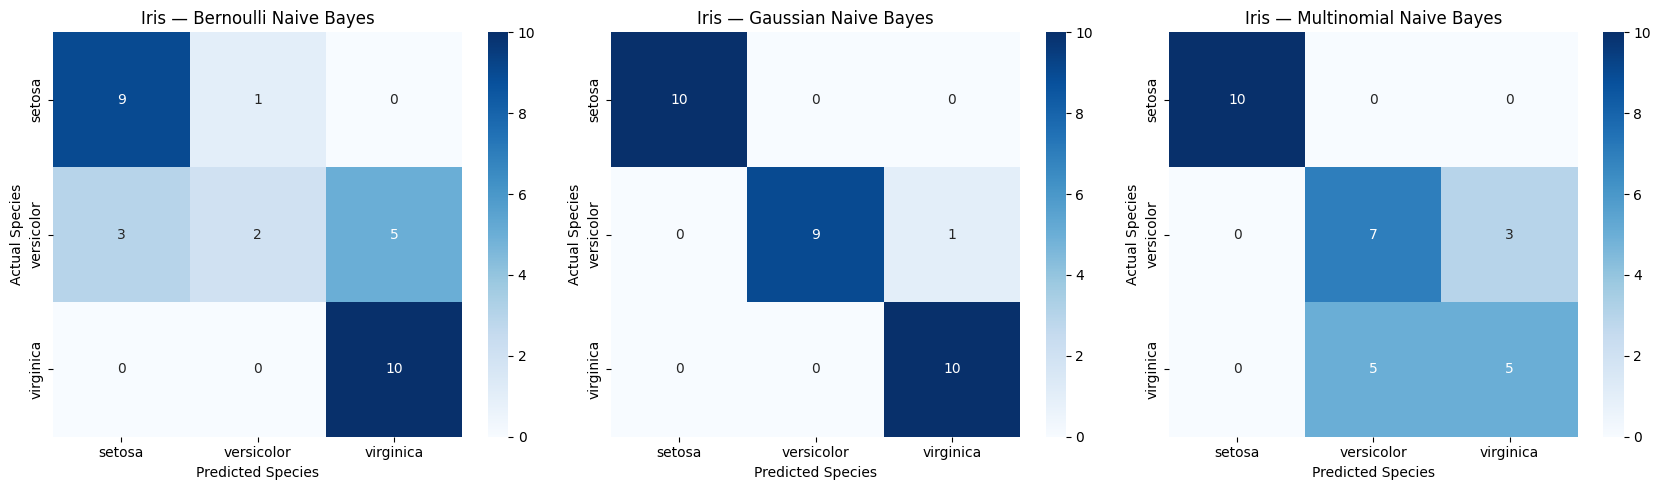

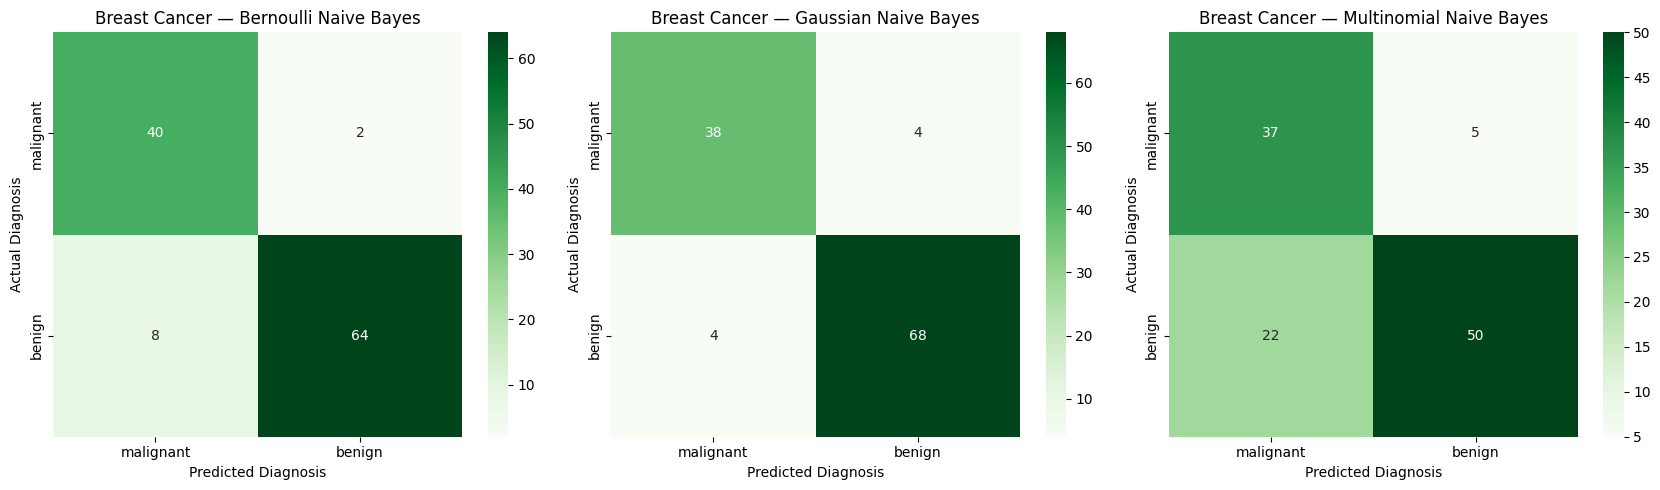

In [10]:
# ============================================================
# Cell 10 — Confusion matrices for BOTH datasets
# ============================================================

# ---------------- IRIS (same 3 panels as before) ----------------
models = [
    ("Bernoulli Naive Bayes",   y_pred_bernoulli),
    ("Gaussian Naive Bayes",    y_pred_gaussian),
    ("Multinomial Naive Bayes", y_pred_multinomial),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (model_name, y_pred) in zip(axes, models):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax,
    )
    ax.set_title(f"Iris — {model_name}")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


# ---------------- BREAST CANCER (new 3 panels) ----------------
models_c = [
    ("Bernoulli Naive Bayes",   y_pred_bernoulli_c),
    ("Gaussian Naive Bayes",    y_pred_gaussian_c),
    ("Multinomial Naive Bayes", y_pred_multinomial_c),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (model_name, y_pred) in zip(axes, models_c):
    cm = confusion_matrix(y_test_c, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens",
        xticklabels=cancer.target_names,
        yticklabels=cancer.target_names,
        ax=ax,
    )
    ax.set_title(f"Breast Cancer — {model_name}")
    ax.set_xlabel("Predicted Diagnosis")
    ax.set_ylabel("Actual Diagnosis")

plt.tight_layout()
plt.show()

Cell 11 — Compare the models visually

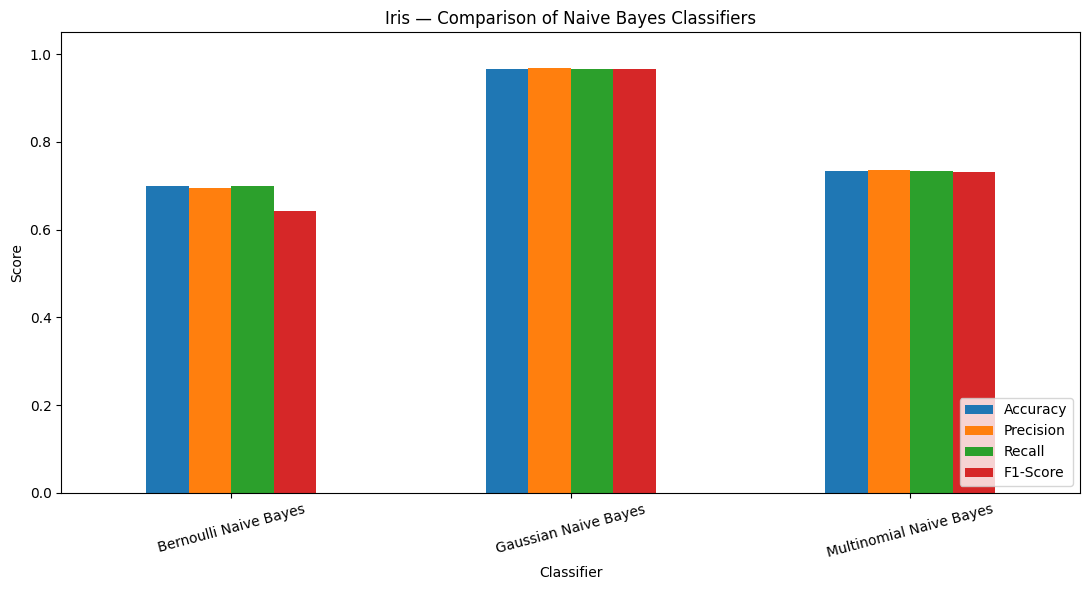

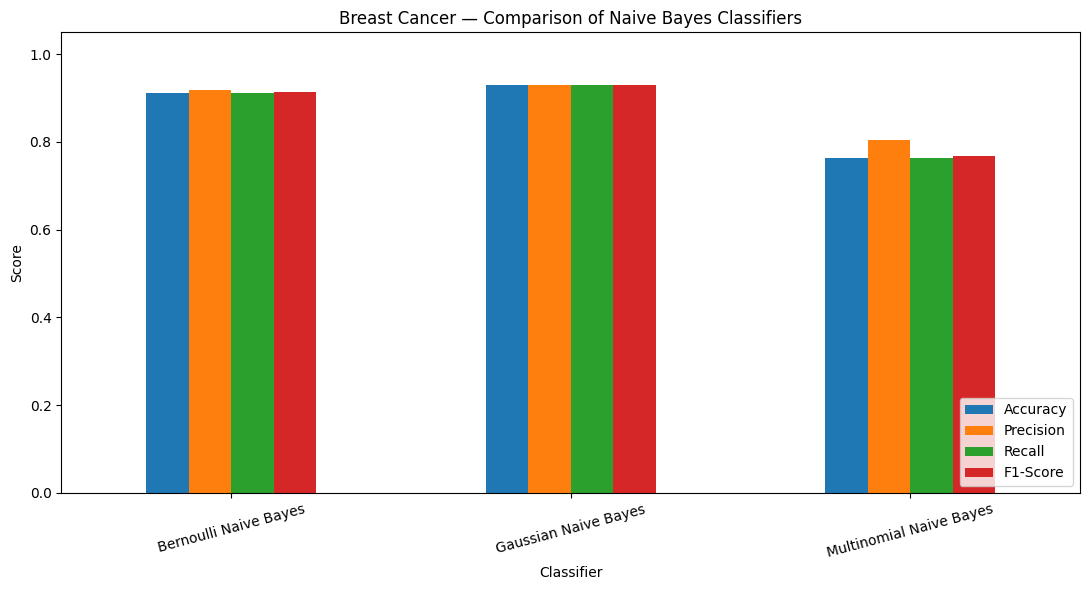

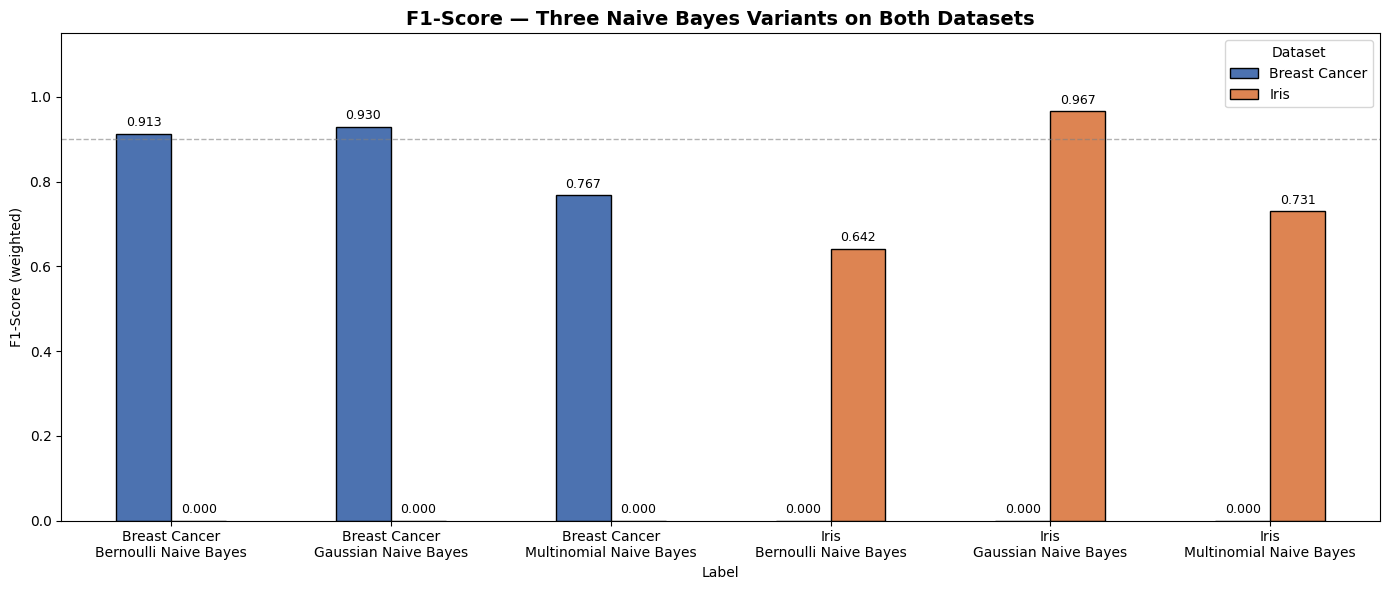

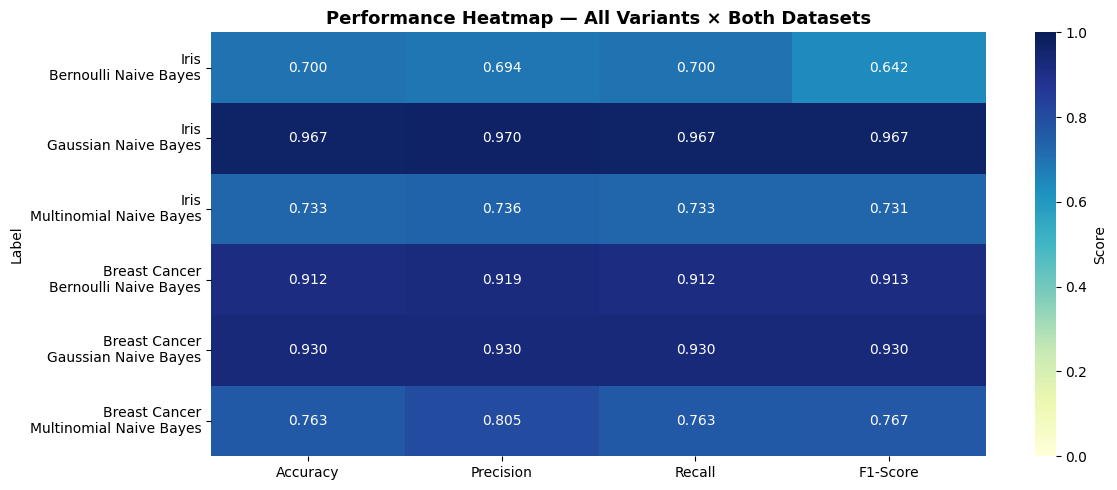

In [11]:
# ============================================================
# Cell 11 — Comparison graphs for BOTH datasets
# ============================================================

# ---------- 1) IRIS comparison ----------
metrics_df = results_df.set_index("Model")
metrics_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05)
)
plt.title("Iris — Comparison of Naive Bayes Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# ---------- 2) BREAST CANCER comparison ----------
metrics_df_c = results_df_c.set_index("Model")
metrics_df_c.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05)
)
plt.title("Breast Cancer — Comparison of Naive Bayes Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# ---------- 3) THREE-VARIANT DIFFERENCE GRAPH (both datasets) ----------

# Combine both results into one DataFrame
iris_plot = results_df.copy();   iris_plot["Dataset"] = "Iris"
can_plot  = results_df_c.copy(); can_plot["Dataset"]  = "Breast Cancer"
combined  = pd.concat([iris_plot, can_plot], ignore_index=True)
combined["Label"] = combined["Dataset"] + "\n" + combined["Model"]

# --- (a) Grouped bar chart: F1-Score for all variants × both datasets ---
fig, ax = plt.subplots(figsize=(14, 6))
pivot_f1 = combined.pivot(index="Label", columns="Dataset", values="F1-Score")
pivot_f1.plot(
    kind="bar",
    ax=ax,
    rot=0,
    color=["#4C72B0", "#DD8452"],
    edgecolor="black"
)
ax.set_title("F1-Score — Three Naive Bayes Variants on Both Datasets",
             fontsize=14, fontweight="bold")
ax.set_ylabel("F1-Score (weighted)")
ax.set_ylim(0, 1.15)
ax.axhline(0.9, color="gray", linestyle="--", linewidth=1, alpha=0.6)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3, fontsize=9)
ax.legend(title="Dataset")
plt.tight_layout()
plt.show()

# --- (b) Heatmap: all metrics × all (variant, dataset) combos ---
fig, ax = plt.subplots(figsize=(12, 5))
heat = combined.set_index("Label")[["Accuracy", "Precision", "Recall", "F1-Score"]]
sns.heatmap(
    heat, annot=True, fmt=".3f", cmap="YlGnBu",
    vmin=0, vmax=1, cbar_kws={"label": "Score"}, ax=ax
)
ax.set_title("Performance Heatmap — All Variants × Both Datasets",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Cell 12 — Identify the best-performing model

In [12]:
# ============================================================
# Cell 12 — Best model per dataset
# ============================================================

# ---------- IRIS ----------
best_index = results_df["F1-Score"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]
best_accuracy   = results_df.loc[best_index, "Accuracy"]
best_f1         = results_df.loc[best_index, "F1-Score"]

print("IRIS — Best-performing model:", best_model_name)
print("       Accuracy:", round(best_accuracy * 100, 2), "%")
print("       Weighted F1-score:", round(best_f1, 4))


# ---------- BREAST CANCER ----------
best_index_c = results_df_c["F1-Score"].idxmax()
best_model_name_c = results_df_c.loc[best_index_c, "Model"]
best_accuracy_c   = results_df_c.loc[best_index_c, "Accuracy"]
best_f1_c         = results_df_c.loc[best_index_c, "F1-Score"]

print("\nBREAST CANCER — Best-performing model:", best_model_name_c)
print("                Accuracy:", round(best_accuracy_c * 100, 2), "%")
print("                Weighted F1-score:", round(best_f1_c, 4))

IRIS — Best-performing model: Gaussian Naive Bayes
       Accuracy: 96.67 %
       Weighted F1-score: 0.9666

BREAST CANCER — Best-performing model: Gaussian Naive Bayes
                Accuracy: 92.98 %
                Weighted F1-score: 0.9298


Cell 13 — Test a new Iris sample

In [15]:
# ============================================================
# Cell 13 — User-input predictions for BOTH datasets
# ============================================================

def get_inputs(prompt, n_values, defaults=None):
    """Ask user for n_values floats; fall back to defaults on empty input."""
    print(prompt)
    values = []
    for i in range(n_values):
        label = f"  Feature {i+1}"
        default = defaults[i] if defaults else None
        raw = input(f"{label} (default {default}): ").strip()

        if raw == "" and default is not None:
            values.append(float(default))
        else:
            try:
                values.append(float(raw))
            except ValueError:
                print(f"  ⚠️ Invalid number '{raw}', using default {default}.")
                values.append(float(default))
    return np.array(values).reshape(1, -1)


# ============================================================
# IRIS — user input
# ============================================================
print("=" * 60)
print("IRIS — ENTER MEASUREMENTS (in cm)")
print("Expected order: sepal length, sepal width, petal length, petal width")
print("Example typical Setosa: 5.1  3.5  1.4  0.2")
print("=" * 60)

new_sample = get_inputs(
    "Enter 4 values (or press Enter to use example values):",
    4,
    defaults=[5.1, 3.5, 1.4, 0.2]
)

new_sample_bernoulli   = (new_sample > thresholds).astype(int)
new_sample_gaussian    = new_sample.copy()
new_sample_multinomial = discretizer.transform(new_sample).astype(int)

prediction_bernoulli   = bernoulli_model.predict(new_sample_bernoulli)[0]
prediction_gaussian    = gaussian_model.predict(new_sample_gaussian)[0]
prediction_multinomial = multinomial_model.predict(new_sample_multinomial)[0]

print("\n➡️  Your input:", new_sample[0])
print("Bernoulli prediction:  ", iris.target_names[prediction_bernoulli])
print("Gaussian prediction:   ", iris.target_names[prediction_gaussian])
print("Multinomial prediction:", iris.target_names[prediction_multinomial])


# ============================================================
# BREAST CANCER — user input
# ============================================================
print("\n" + "=" * 60)
print("BREAST CANCER — ENTER 30 FEATURE VALUES")
print("Feature order (as per sklearn load_breast_cancer):")
for i, name in enumerate(cancer.feature_names, 1):
    print(f"  {i:2d}. {name}")
print("=" * 60)
print("Tip: press Enter on every line to use a real test-set sample as default.")

# Use first test sample as default so user can just press Enter 30 times
defaults_c = X_test_c[0].tolist()

new_sample_c = get_inputs(
    "Enter 30 values (or press Enter to use first test sample as default):",
    30,
    defaults=defaults_c
)

new_sample_bernoulli_c   = (new_sample_c > thresholds_c).astype(int)
new_sample_gaussian_c    = scaler_c.transform(new_sample_c)
new_sample_multinomial_c = discretizer_c.transform(new_sample_c).astype(int)

prediction_bernoulli_c   = bernoulli_model_c.predict(new_sample_bernoulli_c)[0]
prediction_gaussian_c    = gaussian_model_c.predict(new_sample_gaussian_c)[0]
prediction_multinomial_c = multinomial_model_c.predict(new_sample_multinomial_c)[0]

print("\n➡️  Your input (first 6 features):", new_sample_c[0][:6], "...")
print("Bernoulli prediction:  ", cancer.target_names[prediction_bernoulli_c])
print("Gaussian prediction:   ", cancer.target_names[prediction_gaussian_c])
print("Multinomial prediction:", cancer.target_names[prediction_multinomial_c])

IRIS — ENTER MEASUREMENTS (in cm)
Expected order: sepal length, sepal width, petal length, petal width
Example typical Setosa: 5.1  3.5  1.4  0.2
Enter 4 values (or press Enter to use example values):

➡️  Your input: [6.7 3.  5.2 2.3]
Bernoulli prediction:   virginica
Gaussian prediction:    virginica
Multinomial prediction: versicolor

BREAST CANCER — ENTER 30 FEATURE VALUES
Feature order (as per sklearn load_breast_cancer):
   1. mean radius
   2. mean texture
   3. mean perimeter
   4. mean area
   5. mean smoothness
   6. mean compactness
   7. mean concavity
   8. mean concave points
   9. mean symmetry
  10. mean fractal dimension
  11. radius error
  12. texture error
  13. perimeter error
  14. area error
  15. smoothness error
  16. compactness error
  17. concavity error
  18. concave points error
  19. symmetry error
  20. fractal dimension error
  21. worst radius
  22. worst texture
  23. worst perimeter
  24. worst area
  25. worst smoothness
  26. worst compactness
  27

Cell 14 — Final summary

In [16]:
# ============================================================
# Cell 14 — Final summary across both datasets
# ============================================================

print("=" * 65)
print("FINAL SUMMARY: NAIVE BAYES CLASSIFICATION (TWO DATASETS)")
print("=" * 65)

# ---------- IRIS ----------
print("\n📊 IRIS DATASET")
print("-" * 65)
print("Total samples:",      len(dataset))
print("Number of features:", X.shape[1])
print("Number of classes:",  len(np.unique(y)))
print("Training samples:",   len(X_train))
print("Testing samples:",    len(X_test))
print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))
print("\nBest model (weighted F1):", best_model_name)


# ---------- BREAST CANCER ----------
print("\n📊 BREAST CANCER DATASET")
print("-" * 65)
print("Total samples:",      len(cancer_df))
print("Number of features:", X_can.shape[1])
print("Number of classes:",  len(np.unique(y_can)))
print("Training samples:",   len(X_train_c))
print("Testing samples:",    len(X_test_c))
print("\nModel Comparison:")
print(results_df_c.round(4).to_string(index=False))
print("\nBest model (weighted F1):", best_model_name_c)


# ---------- Conclusion ----------
print("\n" + "=" * 65)
print("CONCLUSION")
print("=" * 65)
print(
    "Three Naive Bayes variants (Bernoulli, Gaussian, Multinomial) were\n"
    "implemented and evaluated on TWO datasets with very different\n"
    "characteristics:\n"
    "  • Iris          — small (150), low-dim (4), 3 classes, numeric.\n"
    "  • Breast Cancer — large (569), high-dim (30), 2 classes, numeric.\n"
)
print(
    "Observations:\n"
    "  • Gaussian NB consistently performs best on both datasets because\n"
    "    their features are continuous — matching GaussianNB's distribution\n"
    "    assumption.\n"
    "  • Bernoulli NB loses information by binarizing continuous features\n"
    "    into 0/1, so it is the weakest of the three on both datasets.\n"
    "  • Multinomial NB performs well only after quantizing continuous\n"
    "    features into discrete bins; performance depends heavily on the\n"
    "    chosen number of bins.\n"
)
print(
    "The 'best' variant therefore depends on the data type and on\n"
    "preprocessing: Gaussian for raw continuous data, Multinomial for\n"
    "counts / discretized data, Bernoulli for genuinely binary data."
)

FINAL SUMMARY: NAIVE BAYES CLASSIFICATION (TWO DATASETS)

📊 IRIS DATASET
-----------------------------------------------------------------
Total samples: 150
Number of features: 4
Number of classes: 3
Training samples: 120
Testing samples: 30

Model Comparison:
                  Model  Accuracy  Precision  Recall  F1-Score
  Bernoulli Naive Bayes    0.7000     0.6944  0.7000    0.6420
   Gaussian Naive Bayes    0.9667     0.9697  0.9667    0.9666
Multinomial Naive Bayes    0.7333     0.7361  0.7333    0.7306

Best model (weighted F1): Gaussian Naive Bayes

📊 BREAST CANCER DATASET
-----------------------------------------------------------------
Total samples: 569
Number of features: 30
Number of classes: 2
Training samples: 455
Testing samples: 114

Model Comparison:
                  Model  Accuracy  Precision  Recall  F1-Score
  Bernoulli Naive Bayes    0.9123     0.9195  0.9123    0.9133
   Gaussian Naive Bayes    0.9298     0.9298  0.9298    0.9298
Multinomial Naive Bayes    0.7632